# Layer Tuning Pipeline
## Load Fine-Tuned Model from Drive → Layer Tune → Test & Evaluate

In [ ]:
# ============================================================
# CELL 1: Install Dependencies
# ============================================================
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install -q --no-deps "trl<0.9.0" peft accelerate bitsandbytes
!pip install -q datasets scikit-learn matplotlib seaborn sentencepiece protobuf
print("All dependencies installed ✅")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
All dependencies installed ✅


In [ ]:
# ============================================================
# CELL 2: Imports & Configuration
# ============================================================
import os, gc, random, warnings
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from unsloth import FastModel
from transformers import (
    PreTrainedModel, PretrainedConfig,
    TrainingArguments, Trainer, EarlyStoppingCallback,
)
from transformers.modeling_outputs import SequenceClassifierOutput
from peft import LoraConfig, get_peft_model, TaskType
from datasets import Dataset
from sklearn.metrics import (
    f1_score, accuracy_score, precision_score,
    recall_score, confusion_matrix, classification_report,
)
from sklearn.model_selection import train_test_split

# ─── Reproducibility ──────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# ─── Label Map (must match fine-tune) ─────────────────────────
LABEL2ID = {
    "valid and plausible":     0,
    "valid and implausible":   1,
    "invalid and plausible":   2,
    "invalid and implausible": 3,
}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
NUM_LABELS = 4

# ─── Backbone (same as fine-tune) ─────────────────────────────
MODEL_NAME   = "unsloth/Qwen3-1.7B-unsloth-bnb-4bit"
MAX_SEQ_LEN  = 612
LORA_R       = 16
LORA_ALPHA   = 32
LORA_DROPOUT = 0.2

# ─── Paths ────────────────────────────────────────────────────
SAVED_MODEL_PATH     = "/content/drive/MyDrive/SemEval2026/92model/multilang_4class_unsloth/lora_adapter/pytorch_model.pt"
TRAIN_CSV_PATH       = "/content/train_data_49_51_ratio.csv"
TEST_CSV_PATH        = "/content/test_data_multilang_CSV.csv"
TEST_LABELS_CSV_PATH = "/content/test_data_subtask_3_with_labels.csv"
OUTPUT_DIR           = "/content/semeval_layer_tuned"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
print("Configuration ready ✅")

Device : cuda
GPU    : Tesla T4
Configuration ready ✅


In [ ]:
# ============================================================
# CELL 3: CoT Prompt (identical to fine-tune — do not change)
# ============================================================
COT_SYSTEM_PROMPT = """Classify syllogism. Labels: valid and plausible | valid and implausible | invalid and plausible | invalid and implausible
VALIDITY: conclusion follows logically from premises. PLAUSIBILITY: content matches real-world facts.
Steps: (1) validity: counterexample possible?→invalid else valid (2) plausibility: believable?→plausible else implausible

[EN/DE] All chairs are birds. All birds are furniture. → all chairs are furniture.
V:valid | P:implausible → valid and implausible

[EN/ZH] All dogs are animals. All animals breathe. → all dogs breathe.
V:valid | P:plausible → valid and plausible

[EN/BN] Some fish are shirts. All shirts are cats. → no fish are cats.
V:invalid | P:implausible → invalid and implausible

[EN/FR] Some trees are vehicles. All vehicles are clothes. → no trees are clothes.
V:invalid | P:plausible → invalid and plausible

[EN/IT] Some doctors are shirts. All shirts are fruit. → no doctors are fruit.
V:invalid | P:plausible → invalid and plausible

[EN/ES] All birds are chairs. All chairs are plants. → all birds are plants.
V:valid | P:implausible → valid and implausible

[EN/RU] Some plants are cars. All cars are hammers. → no plants are hammers.
V:invalid | P:plausible → invalid and plausible

[EN/SW] All mammals are doctors. All doctors are furniture. → all mammals are furniture.
V:valid | P:implausible → valid and implausible

[EN/PT] Some dogs are shirts. All shirts are doctors. → no dogs are doctors.
V:invalid | P:implausible → invalid and implausible

[EN/NL] Every human is a robot. Any child is a human. → every child is a robot.
V:valid | P:implausible → valid and implausible

[EN/TE] All apples are vehicles. All vehicles are professions. → all apples are professions.
V:valid | P:implausible → valid and implausible

[EN/ZH-CN] Some shirts are cars. All cars are hammers. → no shirts are hammers.
V:invalid | P:plausible → invalid and plausible"""

def build_cot_input(syllogism: str) -> str:
    return f"{COT_SYSTEM_PROMPT}\n\nSyllogism: {syllogism}\n\nAnalyze and classify:"

print("CoT Prompt ready ✅")

CoT Prompt ready ✅


In [ ]:
# ============================================================
# CELL 4: Mount Drive & Load Saved Fine-Tuned Model
# ============================================================
from google.colab import drive
drive.mount("/content/drive")
print("Google Drive mounted ✅")

gc.collect()
torch.cuda.empty_cache()

# ── Step 1: Rebuild backbone (same as fine-tune) ──────────────
print(f"\nLoading backbone: {MODEL_NAME}")
backbone, tokenizer = FastModel.from_pretrained(
    model_name     = MODEL_NAME,
    max_seq_length = MAX_SEQ_LEN,
    load_in_4bit   = True,
    dtype          = None,
)
if tokenizer.pad_token is None:
    tokenizer.pad_token    = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id
tokenizer.padding_side = "right"
backbone.config.pad_token_id = tokenizer.pad_token_id

# ── Step 2: Apply LoRA (same config as fine-tune) ─────────────
lora_config = LoraConfig(
    r              = LORA_R,
    lora_alpha     = LORA_ALPHA,
    target_modules = "all-linear",
    lora_dropout   = LORA_DROPOUT,
    bias           = "none",
    task_type      = TaskType.FEATURE_EXTRACTION,
)
backbone = get_peft_model(backbone, lora_config)

# ── Step 3: Original SeqCLS wrapper (needed to load weights) ──
class SeqCLSConfig(PretrainedConfig):
    model_type = "unsloth_seqcls"
    def __init__(self, backbone_config=None, num_labels=4, **kwargs):
        super().__init__(**kwargs)
        self.hidden_size = backbone_config.hidden_size if backbone_config else 2048
        self.num_labels  = num_labels
        self.id2label    = ID2LABEL
        self.label2id    = LABEL2ID

class UnslothForSeqCLS(PreTrainedModel):
    config_class = SeqCLSConfig
    def __init__(self, config, backbone):
        super().__init__(config)
        self.backbone   = backbone
        self.classifier = nn.Linear(config.hidden_size, config.num_labels)
        self.loss_fn    = nn.CrossEntropyLoss()
    def forward(self, input_ids=None, attention_mask=None, labels=None, **kwargs):
        out      = self.backbone(input_ids=input_ids, attention_mask=attention_mask,
                                 output_hidden_states=True, **kwargs)
        hidden   = out.hidden_states[-1]
        seq_lens = attention_mask.sum(dim=1) - 1
        pooled   = hidden[torch.arange(hidden.size(0), device=hidden.device), seq_lens]
        logits   = self.classifier(pooled.float())
        loss = self.loss_fn(logits, labels) if labels is not None else None
        return SequenceClassifierOutput(loss=loss, logits=logits)

# ── Step 4: Load saved weights ────────────────────────────────
print(f"\nLoading saved weights from Drive...")
cls_config   = SeqCLSConfig(backbone_config=backbone.config, num_labels=NUM_LABELS)
loaded_model = UnslothForSeqCLS(cls_config, backbone)

saved_state  = torch.load(SAVED_MODEL_PATH, map_location=DEVICE)
missing, unexpected = loaded_model.load_state_dict(saved_state, strict=False)
loaded_model.to(DEVICE)

print(f"  Missing keys    : {len(missing)}")
print(f"  Unexpected keys : {len(unexpected)}")
print("\nFine-tuned model loaded from Drive ✅")

Mounted at /content/drive
Google Drive mounted ✅

Loading backbone: unsloth/Qwen3-1.7B-unsloth-bnb-4bit
==((====))==  Unsloth 2026.6.9: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/1.41G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/237 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (2 outputs left out)

added_tokens.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/4.67k [00:00<?, ?B/s]

unsloth/Qwen3-1.7B-unsloth-bnb-4bit does not have a padding token! Will use pad_token = <|PAD_TOKEN|>.

Loading saved weights from Drive...
  Missing keys    : 0
  Unexpected keys : 965

Fine-tuned model loaded from Drive ✅


In [ ]:
# ============================================================
# CELL 5: Layer Tune Settings  ← ADJUST THESE BETWEEN RUNS
#   Fine-grained parameter-level unfreezing, instead of
#   whole-layer channel tuning.
# ============================================================

# 1. LAYER RANGE  (which transformer layers participate in tuning)
#    Negative index = "last N layers", counted from the end.
#    e.g. -12 → last 12 layers, -8 → last 8 layers, -4 → last 4 layers
#    0 or None → no transformer layers unfrozen (head-only / projection-only)
LAYER_RANGE = -10                     # e.g. -12 / -8 / -4

# 2. PROJECTIONS TO UNFREEZE  (which weight matrices inside each
#    selected layer's attention/MLP block get unfrozen)
#    Choose any subset of:
#      "q_proj", "k_proj", "v_proj"            (attention projections)
#      "up_proj", "down_proj", "gate_proj"     (MLP projections)
PROJECTIONS_TO_UNFREEZE = ["q_proj", "v_proj", "up_proj", "down_proj"]

# 3. HIDDEN SIZE  (size of the extra hidden layer in the new head)
#    Set to None to skip.   Recommended: 512 / 1024 / 2048
HIDDEN_LAYER_SIZE = 1024

# 4. ATTENTION NORM  (unfreeze input_layernorm / post_attention_layernorm
#    inside the selected layers)
UNFREEZE_ATTENTION_NORM = True

# 5. LM HEAD  (unfreeze the backbone's own lm_head / embedding output
#    layer, if the loaded backbone has one)
UNFREEZE_LM_HEAD = False

# ─── Other head-architecture knobs (kept from previous version) ──
DENSE_LAYER_SIZE  = 256
PROJECTION_RATE   = 0.2          # dropout rate inside the new head

# ─── Layer Tune Training Hyperparameters ──────────────────────
LT_LEARNING_RATE  = 2e-4
LT_MAX_EPOCHS     = 11
LT_PATIENCE       = 8
BATCH_SIZE        = 2
GRAD_ACCUM        = 4
TEMPERATURE       = 0.9

print("="*60)
print("LAYER TUNE CONFIGURATION")
print("="*60)
print(f"  Layer Range              : {LAYER_RANGE}  (last N transformer layers)")
print(f"  Projections to Unfreeze  : {PROJECTIONS_TO_UNFREEZE}")
print(f"  Hidden Layer Size (head) : {HIDDEN_LAYER_SIZE}")
print(f"  Unfreeze Attention Norm  : {UNFREEZE_ATTENTION_NORM}")
print(f"  Unfreeze LM Head         : {UNFREEZE_LM_HEAD}")
print(f"  Dense Layer Size (head)  : {DENSE_LAYER_SIZE}")
print(f"  Projection Rate (dropout): {PROJECTION_RATE}")
print(f"  LR / Epochs              : {LT_LEARNING_RATE} / {LT_MAX_EPOCHS}  (patience={LT_PATIENCE})")
print("="*60)

LAYER TUNE CONFIGURATION
  Layer Range              : -10  (last N transformer layers)
  Projections to Unfreeze  : ['q_proj', 'v_proj', 'up_proj', 'down_proj']
  Hidden Layer Size (head) : 1024
  Unfreeze Attention Norm  : True
  Unfreeze LM Head         : False
  Dense Layer Size (head)  : 256
  Projection Rate (dropout): 0.2
  LR / Epochs              : 0.0002 / 11  (patience=8)


In [ ]:
# ============================================================
# CELL 6: Build Layer-Tuned Model
#   Takes the loaded backbone and attaches a new configurable
#   classification head, then unfreezes only the specific
#   parameters requested in Cell 5 (layer range × projections ×
#   attention norm × lm_head).
# ============================================================

def _unwrap_to_transformer(backbone):
    """Unwrap PEFT/LoRA wrapper to reach the base transformer module
       that exposes a `.layers` (or equivalent) attribute."""
    base = backbone
    for attr in ['base_model', 'model']:
        if hasattr(base, attr):
            base = getattr(base, attr)
    return base


def _find_layer_list(base):
    """Locate the transformer's list of decoder/encoder layers."""
    for attr in ['layers', 'encoder', 'h', 'blocks']:
        cand = getattr(base, attr, None)
        if cand is not None and hasattr(cand, '__len__'):
            return cand
        elif cand is not None and hasattr(cand, 'layer'):
            return cand.layer
    return None


def apply_parameter_level_unfreeze(
    backbone,
    layer_range,
    projections_to_unfreeze,
    unfreeze_attention_norm,
    unfreeze_lm_head,
):
    """
    Freezes the entire backbone, then selectively unfreezes:
      • only the named projection matrices (q/k/v/up/down/gate)
        inside the last |layer_range| transformer layers
      • attention/MLP norm layers in those same layers (optional)
      • the backbone's lm_head, if present (optional)
    Returns (num_layers_touched, total_layers, unfrozen_param_count).
    """
    # 1. Freeze everything first
    for p in backbone.parameters():
        p.requires_grad = False

    base       = _unwrap_to_transformer(backbone)
    layer_list = _find_layer_list(base)

    num_layers_touched = 0
    total_layers        = len(layer_list) if layer_list is not None else 0

    if layer_list is not None and layer_range not in (0, None):
        n = abs(int(layer_range))
        n = min(n, total_layers)
        start_idx = total_layers - n
        num_layers_touched = n

        for i, layer in enumerate(layer_list):
            if i < start_idx:
                continue
            for name, param in layer.named_parameters():
                lname = name.lower()

                # ── Projection matrices ────────────────────────
                if any(proj in lname for proj in projections_to_unfreeze):
                    param.requires_grad = True

                # ── Attention / MLP norm layers ────────────────
                if unfreeze_attention_norm and ("norm" in lname or "ln" in lname):
                    param.requires_grad = True

    # 2. lm_head (only relevant if backbone retains a causal LM head)
    if unfreeze_lm_head:
        lm_head = getattr(base, "lm_head", None) or getattr(backbone, "lm_head", None)
        if lm_head is not None:
            for p in lm_head.parameters():
                p.requires_grad = True
        else:
            print("  [INFO] No lm_head found on backbone — skipping lm_head unfreeze.")

    unfrozen_count = sum(p.numel() for p in backbone.parameters() if p.requires_grad)
    return num_layers_touched, total_layers, unfrozen_count


class LayerTunedSeqCLS(nn.Module):
    """
    pool → [Linear(hidden_layer_size) + LN + GELU + Dropout]
         → [Linear(dense_layer_size)  + LN + GELU + Dropout]
         →  Linear(num_labels)
    Layers in [] are skipped when their size is set to None.
    Backbone unfreezing is controlled entirely by the parameter-level
    settings from Cell 5 (layer range, projections, norm, lm_head).
    """
    def __init__(self, backbone, backbone_hidden_size, num_labels,
                 hidden_layer_size, dense_layer_size, projection_rate,
                 layer_range, projections_to_unfreeze,
                 unfreeze_attention_norm, unfreeze_lm_head):
        super().__init__()
        self.backbone = backbone
        self.loss_fn  = nn.CrossEntropyLoss()

        # ── Build head dynamically ─────────────────────────────
        layers = []
        in_dim = backbone_hidden_size

        if hidden_layer_size is not None:
            layers += [nn.Linear(in_dim, hidden_layer_size),
                       nn.LayerNorm(hidden_layer_size), nn.GELU(),
                       nn.Dropout(projection_rate)]
            in_dim = hidden_layer_size

        if dense_layer_size is not None:
            layers += [nn.Linear(in_dim, dense_layer_size),
                       nn.LayerNorm(dense_layer_size), nn.GELU(),
                       nn.Dropout(projection_rate)]
            in_dim = dense_layer_size

        layers.append(nn.Linear(in_dim, num_labels))
        self.classifier = nn.Sequential(*layers)

        # ── Parameter-level backbone unfreezing ─────────────────
        touched, total, unfrozen = apply_parameter_level_unfreeze(
            self.backbone,
            layer_range              = layer_range,
            projections_to_unfreeze  = projections_to_unfreeze,
            unfreeze_attention_norm  = unfreeze_attention_norm,
            unfreeze_lm_head         = unfreeze_lm_head,
        )
        print(f"  Layer range {layer_range}: touched {touched}/{total} transformer layers")
        print(f"  Projections unfrozen   : {projections_to_unfreeze}")
        print(f"  Attention norm unfrozen: {unfreeze_attention_norm}")
        print(f"  LM head unfrozen       : {unfreeze_lm_head}")
        print(f"  Backbone trainable params: {unfrozen:,}")

        # Always keep the new classifier head trainable
        for p in self.classifier.parameters():
            p.requires_grad = True

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kwargs):
        out      = self.backbone(input_ids=input_ids, attention_mask=attention_mask,
                                 output_hidden_states=True, **kwargs)
        hidden   = out.hidden_states[-1]
        seq_lens = attention_mask.sum(dim=1) - 1
        pooled   = hidden[torch.arange(hidden.size(0), device=hidden.device), seq_lens]
        logits   = self.classifier(pooled.float())
        loss = self.loss_fn(logits, labels) if labels is not None else None
        return SequenceClassifierOutput(loss=loss, logits=logits)

    @property
    def device(self):
        return next(self.parameters()).device


gc.collect(); torch.cuda.empty_cache()

layer_tuned_model = LayerTunedSeqCLS(
    backbone                = loaded_model.backbone,
    backbone_hidden_size    = loaded_model.config.hidden_size,
    num_labels              = NUM_LABELS,
    hidden_layer_size       = HIDDEN_LAYER_SIZE,
    dense_layer_size        = DENSE_LAYER_SIZE,
    projection_rate         = PROJECTION_RATE,
    layer_range             = LAYER_RANGE,
    projections_to_unfreeze = PROJECTIONS_TO_UNFREEZE,
    unfreeze_attention_norm = UNFREEZE_ATTENTION_NORM,
    unfreeze_lm_head        = UNFREEZE_LM_HEAD,
).to(DEVICE)

total_params     = sum(p.numel() for p in layer_tuned_model.parameters())
trainable_params = sum(p.numel() for p in layer_tuned_model.parameters() if p.requires_grad)
print(f"\nTotal params     : {total_params:,}")
print(f"Trainable params : {trainable_params:,}  ({100*trainable_params/total_params:.2f}%)")
print("\nClassification head:")
for i, l in enumerate(layer_tuned_model.classifier): print(f"  [{i}] {l}")
print("\nLayer-tuned model ready ✅")

  Layer range -10: touched 0/0 transformer layers
  Projections unfrozen   : ['q_proj', 'v_proj', 'up_proj', 'down_proj']
  Attention norm unfrozen: True
  LM head unfrozen       : False
  Backbone trainable params: 0

Total params     : 1,054,603,012
Trainable params : 2,364,164  (0.22%)

Classification head:
  [0] Linear(in_features=2048, out_features=1024, bias=True)
  [1] LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  [2] GELU(approximate='none')
  [3] Dropout(p=0.2, inplace=False)
  [4] Linear(in_features=1024, out_features=256, bias=True)
  [5] LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  [6] GELU(approximate='none')
  [7] Dropout(p=0.2, inplace=False)
  [8] Linear(in_features=256, out_features=4, bias=True)

Layer-tuned model ready ✅


In [ ]:
# ============================================================
# CELL 7: Tokenize Train / Val Datasets
# ============================================================
train_df = pd.read_csv(TRAIN_CSV_PATH)
train_df["label"] = train_df["label"].str.strip()
train_df["label_id"] = train_df["label"].map(LABEL2ID)

train_split, val_split = train_test_split(
    train_df, test_size=0.15, random_state=SEED, stratify=train_df["label_id"]
)
train_split = train_split.reset_index(drop=True)
val_split   = val_split.reset_index(drop=True)

def build_cls_dataset(df, has_labels=True):
    ids, masks, labels = [], [], []
    for _, row in df.iterrows():
        enc = tokenizer(build_cot_input(str(row["syllogism"])),
                        max_length=MAX_SEQ_LEN, padding="max_length",
                        truncation=True, return_tensors="pt")
        ids.append(enc["input_ids"].squeeze().tolist())
        masks.append(enc["attention_mask"].squeeze().tolist())
        if has_labels: labels.append(int(row["label_id"]))
    out = {"input_ids": ids, "attention_mask": masks}
    if has_labels: out["labels"] = labels
    return Dataset.from_dict(out)

print("Tokenizing datasets...")
train_dataset = build_cls_dataset(train_split)
val_dataset   = build_cls_dataset(val_split)
print(f"  Train : {len(train_dataset)} samples")
print(f"  Val   : {len(val_dataset)} samples")
print("Datasets ready ✅")

Tokenizing datasets...
  Train : 850 samples
  Val   : 150 samples
Datasets ready ✅


In [ ]:
# ============================================================
# CELL 8: Layer Tuning Training
# ============================================================
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"f1": f1_score(labels, preds, average="macro", zero_division=0),
            "accuracy": accuracy_score(labels, preds)}

warmup_steps = max(1, int(0.1 * len(train_dataset) / (BATCH_SIZE * GRAD_ACCUM)))

lt_args = TrainingArguments(
    output_dir                  = OUTPUT_DIR,
    num_train_epochs            = LT_MAX_EPOCHS,
    per_device_train_batch_size = BATCH_SIZE,
    per_device_eval_batch_size  = BATCH_SIZE,
    gradient_accumulation_steps = GRAD_ACCUM,
    learning_rate               = LT_LEARNING_RATE,
    lr_scheduler_type           = "cosine",
    warmup_steps                = warmup_steps,
    optim                       = "adamw_8bit",
    weight_decay                = 0.01,
    max_grad_norm               = 1.0,
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    metric_for_best_model       = "f1",
    greater_is_better           = True,
    load_best_model_at_end      = True,
    save_total_limit            = 2,
    bf16=False, fp16=False,
    logging_steps               = 5,
    report_to                   = "none",
    seed                        = SEED,
    dataloader_num_workers      = 0,
    gradient_checkpointing      = False,
    remove_unused_columns       = False,
)

# ── Force .bin checkpoints instead of safetensors ──────────────
# embed_tokens / lm_head share memory (tied weights), and safetensors
# refuses to save two keys pointing at the same tensor. This transformers
# version doesn't accept save_safetensors as a constructor kwarg, so we
# set the attribute directly after construction instead.
if hasattr(lt_args, "save_safetensors"):
    lt_args.save_safetensors = False
else:
    print("[WARN] TrainingArguments has no save_safetensors attribute on this version.")

trainer = Trainer(
    model           = layer_tuned_model,
    args            = lt_args,
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
    callbacks       = [EarlyStoppingCallback(early_stopping_patience=LT_PATIENCE,
                                             early_stopping_threshold=0.001)],
)

# ── Belt-and-suspenders: monkeypatch save to always use torch.save ────
# Some transformers/accelerate versions ignore save_safetensors in certain
# code paths during checkpointing. This guarantees .bin is used regardless.
import types
_original_save = trainer.save_model
def _save_model_no_safetensors(self, output_dir=None, _internal_call=False):
    self.args.save_safetensors = False
    return _original_save(output_dir=output_dir, _internal_call=_internal_call)
trainer.save_model = types.MethodType(_save_model_no_safetensors, trainer)

print("="*60)
print("LAYER TUNING — START")
print(f"  Layer Range={LAYER_RANGE}  Projections={PROJECTIONS_TO_UNFREEZE}")
print(f"  Hidden={HIDDEN_LAYER_SIZE}  Dense={DENSE_LAYER_SIZE}  Proj.rate={PROJECTION_RATE}")
print(f"  AttnNorm={UNFREEZE_ATTENTION_NORM}  LMHead={UNFREEZE_LM_HEAD}")
print(f"  LR={LT_LEARNING_RATE}  Epochs={LT_MAX_EPOCHS}  Trainable={trainable_params:,}")
print("="*60)

lt_result = trainer.train()

print("\n" + "="*60)
print(f"LAYER TUNING COMPLETE — Loss: {lt_result.training_loss:.4f}")
print("="*60)

[WARN] TrainingArguments has no save_safetensors attribute on this version.
LAYER TUNING — START
  Layer Range=-10  Projections=['q_proj', 'v_proj', 'up_proj', 'down_proj']
  Hidden=1024  Dense=256  Proj.rate=0.2
  AttnNorm=True  LMHead=False
  LR=0.0002  Epochs=11  Trainable=2,364,164


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 850 | Num Epochs = 11 | Total steps = 1,177
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 2,364,164 of 1,054,603,012 (0.22% trained)
Unsloth: Not an error, but LayerTunedSeqCLS does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss,F1,Accuracy
1,0.235882,1.443477,0.516172,0.553333


RuntimeError: 
            Some tensors share memory, this will lead to duplicate memory on disk and potential differences when loading them again: [{'backbone.base_model.model.lm_head.weight', 'backbone.base_model.model.model.embed_tokens.weight'}].
            A potential way to correctly save your model is to use `save_model`.
            More information at https://huggingface.co/docs/safetensors/torch_shared_tensors
            

In [ ]:
# ============================================================
# CELL 9: Predict on Test Set
# ============================================================
test_df = pd.read_csv(TEST_CSV_PATH)
print(f"Running inference on {len(test_df)} test samples...")

layer_tuned_model.eval()
predictions = []
n = len(test_df)

for i in range(0, n, 8):
    batch  = test_df["syllogism"].iloc[i:i+8].tolist()
    inputs = tokenizer(
        [build_cot_input(s) for s in batch],
        max_length=MAX_SEQ_LEN, padding="max_length",
        truncation=True, return_tensors="pt",
    ).to(DEVICE)
    with torch.no_grad():
        logits = layer_tuned_model(**inputs).logits / TEMPERATURE
        predictions.extend(torch.argmax(logits, dim=-1).cpu().tolist())
    done = min(i+8, n)
    if done % 40 == 0 or done == n:
        print(f"  [{done:>4}/{n}] predicted...")

pred_labels = [ID2LABEL[p] for p in predictions]
pred_df     = test_df.copy()
pred_df["predicted_label"] = pred_labels

pred_path = os.path.join(OUTPUT_DIR, "test_predictions.csv")
pred_df.to_csv(pred_path, index=False)
print(f"\nPredicted label distribution:")
print(pd.Series(pred_labels).value_counts())
print(f"\nPredictions saved → {pred_path} ✅")

Running inference on 192 test samples...
  [  40/192] predicted...
  [  80/192] predicted...
  [ 120/192] predicted...
  [ 160/192] predicted...
  [ 192/192] predicted...

Predicted label distribution:
valid and implausible      50
invalid and implausible    48
invalid and plausible      47
valid and plausible        47
Name: count, dtype: int64

Predictions saved → /content/semeval_layer_tuned/test_predictions.csv ✅


EVALUATION RESULTS
  ① Macro F1        : 0.9529   ← SemEval primary metric
  ② Macro Precision : 0.9532
  ③ Macro Recall    : 0.9531
  ④ Accuracy        : 0.9531

🎯 Macro F1: 95.29%  ✅ TARGET MET (>85%)

PER-CLASS REPORT
                         precision    recall  f1-score   support

    valid and plausible       0.98      0.96      0.97        48
  valid and implausible       0.94      0.98      0.96        48
  invalid and plausible       0.91      0.93      0.92        46
invalid and implausible       0.98      0.94      0.96        50

               accuracy                           0.95       192
              macro avg       0.95      0.95      0.95       192
           weighted avg       0.95      0.95      0.95       192



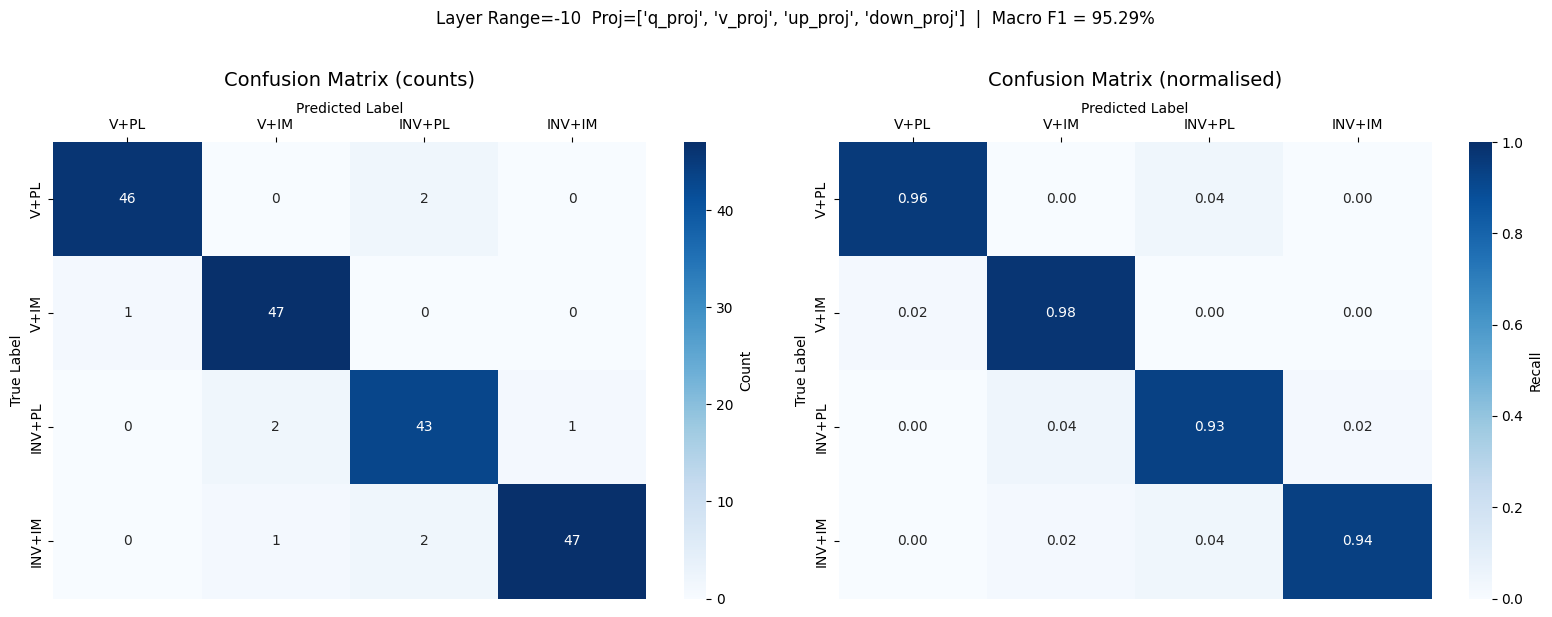

Confusion matrix saved → /content/semeval_layer_tuned/confusion_matrix.png ✅


In [ ]:
# ============================================================
# CELL 10: Evaluate — 4 Metrics + Confusion Matrix
# ============================================================
gold_df = pd.read_csv(TEST_LABELS_CSV_PATH)
gold_df["label"] = gold_df["label"].str.strip()

eval_df = pred_df.merge(gold_df[["id", "label"]], on="id", how="inner")
eval_df = eval_df.rename(columns={"label": "true_label"})
assert len(eval_df) == len(pred_df), "Merge mismatch — check IDs"

y_true  = eval_df["true_label"].tolist()
y_pred  = eval_df["predicted_label"].tolist()
classes = list(LABEL2ID.keys())

# ── 4 Core Metrics ────────────────────────────────────────────
f1_macro  = f1_score(y_true, y_pred, average="macro",    labels=classes, zero_division=0)
precision = precision_score(y_true, y_pred, average="macro", labels=classes, zero_division=0)
recall    = recall_score(y_true, y_pred,    average="macro", labels=classes, zero_division=0)
accuracy  = accuracy_score(y_true, y_pred)

print("="*60)
print("EVALUATION RESULTS")
print("="*60)
print(f"  ① Macro F1        : {f1_macro:.4f}   ← SemEval primary metric")
print(f"  ② Macro Precision : {precision:.4f}")
print(f"  ③ Macro Recall    : {recall:.4f}")
print(f"  ④ Accuracy        : {accuracy:.4f}")
print("="*60)
print(f"\n🎯 Macro F1: {f1_macro*100:.2f}%  "
      f"{'✅ TARGET MET (>85%)' if f1_macro >= 0.85 else '❌ Below 85% — tune hyperparams'}")

print("\n" + "="*60)
print("PER-CLASS REPORT")
print("="*60)
print(classification_report(y_true, y_pred, labels=classes, zero_division=0))

# ── Confusion Matrix ──────────────────────────────────────────
short_labels = ["V+PL", "V+IM", "INV+PL", "INV+IM"]
cm      = confusion_matrix(y_true, y_pred, labels=classes)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt="d", ax=axes[0],
            xticklabels=short_labels, yticklabels=short_labels,
            cmap="Blues", cbar_kws={"label": "Count"})
axes[0].set_title("Confusion Matrix (counts)", fontsize=14, pad=12)
axes[0].set_ylabel("True Label"); axes[0].set_xlabel("Predicted Label")
axes[0].xaxis.set_label_position("top"); axes[0].xaxis.tick_top()

sns.heatmap(cm_norm, annot=True, fmt=".2f", ax=axes[1],
            xticklabels=short_labels, yticklabels=short_labels,
            cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "Recall"})
axes[1].set_title("Confusion Matrix (normalised)", fontsize=14, pad=12)
axes[1].set_ylabel("True Label"); axes[1].set_xlabel("Predicted Label")
axes[1].xaxis.set_label_position("top"); axes[1].xaxis.tick_top()

plt.suptitle(
    f"Layer Range={LAYER_RANGE}  Proj={PROJECTIONS_TO_UNFREEZE}  "
    f"|  Macro F1 = {f1_macro*100:.2f}%",
    fontsize=12, y=1.02
)
plt.tight_layout()
cm_path = os.path.join(OUTPUT_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Confusion matrix saved → {cm_path} ✅")

In [ ]:
# ============================================================
# CELL 11: Per-Language F1
# ============================================================
print("="*55)
print("PER-LANGUAGE MACRO F1")
print("="*55)
lang_rows = []
for lang, grp in eval_df.groupby("lang"):
    lf1 = f1_score(grp["true_label"], grp["predicted_label"],
                   average="macro", labels=classes, zero_division=0)
    lacc = accuracy_score(grp["true_label"], grp["predicted_label"])
    lang_rows.append({"lang": lang, "n": len(grp), "macro_f1": lf1, "accuracy": lacc})
    print(f"  {lang:<10} n={len(grp):>3}  f1={lf1:.4f}  acc={lacc:.4f}")
print("="*55)

lang_df = pd.DataFrame(lang_rows).sort_values("macro_f1", ascending=False)
print("✅ Per-language results computed")

PER-LANGUAGE MACRO F1
  bn         n= 17  f1=0.9143  acc=0.9412
  de         n= 18  f1=1.0000  acc=1.0000
  es         n= 18  f1=0.9451  acc=0.9444
  fr         n= 18  f1=0.9444  acc=0.9444
  it         n= 18  f1=0.8816  acc=0.8889
  nl         n= 17  f1=0.9365  acc=0.9412
  pt         n= 17  f1=0.9495  acc=0.9412
  ru         n= 17  f1=1.0000  acc=1.0000
  sw         n= 17  f1=0.9000  acc=0.9412
  te         n= 17  f1=1.0000  acc=1.0000
  zh-CN      n= 18  f1=0.8889  acc=0.9444
✅ Per-language results computed


In [ ]:
# ============================================================
# CELL 12: Save Model + Report to Drive  (saved LAST, after
#          evaluation, so the saved checkpoint is whatever
#          version you just measured)
# ============================================================
import shutil, time

LT_SAVE_DIR = (
    f"/content/drive/MyDrive/SemEval2026/layer_tuned-10/"
    f"LR{LAYER_RANGE}_PROJ{'-'.join(PROJECTIONS_TO_UNFREEZE)}"
    f"_H{HIDDEN_LAYER_SIZE}_D{DENSE_LAYER_SIZE}"
    f"_AN{int(UNFREEZE_ATTENTION_NORM)}_LMH{int(UNFREEZE_LM_HEAD)}"
)
os.makedirs(LT_SAVE_DIR, exist_ok=True)
time.sleep(2)

torch.save(layer_tuned_model.state_dict(),
           os.path.join(LT_SAVE_DIR, "pytorch_model.pt"))
tokenizer.save_pretrained(os.path.join(LT_SAVE_DIR, "tokenizer"))

pd.DataFrame([{
    "LAYER_RANGE": LAYER_RANGE,
    "PROJECTIONS_TO_UNFREEZE": ",".join(PROJECTIONS_TO_UNFREEZE),
    "HIDDEN_LAYER_SIZE": HIDDEN_LAYER_SIZE, "DENSE_LAYER_SIZE": DENSE_LAYER_SIZE,
    "PROJECTION_RATE": PROJECTION_RATE,
    "UNFREEZE_ATTENTION_NORM": UNFREEZE_ATTENTION_NORM,
    "UNFREEZE_LM_HEAD": UNFREEZE_LM_HEAD,
    "LT_LEARNING_RATE": LT_LEARNING_RATE,
}]).to_csv(os.path.join(LT_SAVE_DIR, "config.csv"), index=False)

# ── Excel report ──────────────────────────────────────────────
report_path = os.path.join(OUTPUT_DIR, "performance_report.xlsx")
summary_df  = pd.DataFrame([{
    "LAYER_RANGE": LAYER_RANGE,
    "PROJECTIONS": ",".join(PROJECTIONS_TO_UNFREEZE),
    "HIDDEN_LAYER_SIZE": HIDDEN_LAYER_SIZE, "DENSE_LAYER_SIZE": DENSE_LAYER_SIZE,
    "ATTN_NORM_UNFROZEN": UNFREEZE_ATTENTION_NORM, "LM_HEAD_UNFROZEN": UNFREEZE_LM_HEAD,
    "LT_LEARNING_RATE": LT_LEARNING_RATE,
    "Macro_F1": round(f1_macro, 4),  "Macro_Precision": round(precision, 4),
    "Macro_Recall": round(recall, 4), "Accuracy": round(accuracy, 4),
}])
with pd.ExcelWriter(report_path, engine="openpyxl") as w:
    summary_df.to_excel(w, sheet_name="Summary",      index=False)
    lang_df.to_excel(   w, sheet_name="Per_Language", index=False)

# Copy all outputs to Drive
for f in [report_path, cm_path, pred_path]:
    shutil.copy(f, LT_SAVE_DIR)

from google.colab import files
files.download(report_path)

print(f"\nAll outputs saved → {LT_SAVE_DIR}")
print("\n" + "="*60)
print("PIPELINE COMPLETE ✅")
print(f"  ① Macro F1        : {f1_macro:.4f}")
print(f"  ② Macro Precision : {precision:.4f}")
print(f"  ③ Macro Recall    : {recall:.4f}")
print(f"  ④ Accuracy        : {accuracy:.4f}")
print("="*60)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/SemEval2026/layer_tuned-10/LR-10_PROJq_proj-v_proj-up_proj-down_proj_H1024_D256_AN1_LMH0/tokenizer/tokenizer_config.json.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All outputs saved → /content/drive/MyDrive/SemEval2026/layer_tuned-10/LR-10_PROJq_proj-v_proj-up_proj-down_proj_H1024_D256_AN1_LMH0

PIPELINE COMPLETE ✅
  ① Macro F1        : 0.9529
  ② Macro Precision : 0.9532
  ③ Macro Recall    : 0.9531
  ④ Accuracy        : 0.9531
